## Lab 16 — Decision Trees: Classification and Regression

### Instructions

Calculate a split, fit a small tree, and interpret its predictions. Then build simple models for busy hours
and rental counts. The short lecture datasets explain the mechanics; the public rental dataset shows their application.
**Prerequisites:** basic Python, pandas, and train/validation evaluation.


The notebook uses short code cells and direct `fit`, `predict`, and `score` calls.
This instructor edition contains completed code, expected answers, and reference outputs.
Distribute only the student edition. Restart and run all cells before teaching.

The dataset downloads automatically. If downloading fails, download the UCI ZIP from the link below,
upload `hour.csv` through Colab's Files pane, and rerun the loading cell.


### Industry Problem Statement — Bike Rental Demand

A shared-bike service such as **Lime, whose vehicles can be rented through Uber**, needs to plan for changes in demand.
Too little preparation can leave customers without bikes; unnecessary preparation uses operating resources.

Use decision trees to answer two questions:

1. **Classification:** Will an hour have at least **300 rentals**?
2. **Regression:** How many rentals are expected during that hour?

Use real public **Capital Bikeshare** records from 2011–2012. Uber and Lime provide industry context;
these are not their data or internal models. The 300-rental threshold is a fixed classroom assumption.

The output is an hourly demand report, not a station-level allocation plan. The data contain observed total rentals,
not lost requests. Weather is recorded historical weather; a future-hour service would need prediction-time forecasts.

[Industry context](https://help.li.me/hc/en-us/articles/1260805266589-Renting-Lime-vehicles-with-Uber) ·
[Public dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)


## Step 1: Import Libraries

For every model, use the same sequence: **create → fit → predict → evaluate**.
For a classifier, `.score()` returns accuracy. For regression, calculate MSE explicitly.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.tree import plot_tree, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error

print("scikit-learn version:", sklearn.__version__)


scikit-learn version: 1.9.1


## Step 2: Understand How a Tree Chooses a Split

Start with the six NST lecture records. Keep Student outside X. Placement is 0 or 1.
The busy-hour model will use the same classification calculation.

$$Gini = 1 - \sum_k p_k^2$$

$$Weighted\ Gini = \frac{n_L}{n}Gini_L + \frac{n_R}{n}Gini_R$$

A lower weighted Gini means purer child groups. Test numerical thresholds halfway between consecutive distinct values.


In [ ]:
nst = pd.DataFrame({
    'Student': ['S1', 'S2', 'S3', 'S4', 'S5', 'S6'],
    'Hours': [2, 4, 6, 5, 7, 3],
    'Attendance': [60, 80, 90, 50, 68, 85],
    'Placement': [0, 1, 1, 0, 0, 0],
})
X_nst = nst[['Hours', 'Attendance']]
y_nst = nst['Placement']
display(nst)


,Student,Hours,Attendance,Placement
0,S1,2,60,0
1,S2,4,80,1
2,S3,6,90,1
3,S4,5,50,0
4,S5,7,68,0
5,S6,3,85,0


### TODO 16.1

Complete the two lines in the Gini function. The candidate-search loop is supplied next.


In [ ]:
# TODO 16.1 — Implement the Gini impurity function.
# Instructions:
# 1. If labels is empty, return 0.0.
# 2. Calculate the proportion of each class.
# 3. Return 1 minus the sum of the squared class proportions.
def gini(labels):
    # TODO: write the Gini impurity logic here.
    pass

print("Parent Gini:", gini(y_nst))

Parent Gini: 0.4444444444444444


In [ ]:
# Supplied self-checks and results
assert np.isclose(gini([0, 0]), 0)
assert np.isclose(gini([0, 1]), 0.5)
assert np.isclose(gini(y_nst), 4/9)


In [ ]:
# Supplied loop: compare every midpoint for each numerical feature.
results = []
for feature in X_nst.columns:
    values = np.sort(X_nst[feature].unique())
    thresholds = (values[:-1] + values[1:]) / 2
    for threshold in thresholds:
        left = X_nst[feature] <= threshold
        left_weight = left.sum() / len(y_nst)
        score = left_weight * gini(y_nst[left]) + (1-left_weight) * gini(y_nst[~left])
        results.append([feature, threshold, score])

split_table = pd.DataFrame(results, columns=["feature", "threshold", "weighted_gini"])
display(split_table.sort_values("weighted_gini"))


,feature,threshold,weighted_gini
7,Attendance,74.0,0.222222
9,Attendance,87.5,0.266667
1,Hours,3.5,0.333333
6,Attendance,64.0,0.333333
0,Hours,2.5,0.400000
4,Hours,6.5,0.400000
5,Attendance,55.0,0.400000
3,Hours,5.5,0.416667
8,Attendance,82.5,0.416667
2,Hours,4.5,0.444444


In [ ]:
# Check the next split inside the higher-attendance group.
group = nst[nst["Attendance"] > 74]
print("Hours <= 3.5 Gini:", gini(group.loc[group["Hours"] <= 3.5, "Placement"]))
print("Hours > 3.5 Gini:", gini(group.loc[group["Hours"] > 3.5, "Placement"]))


Hours <= 3.5 Gini: 0.0
Hours > 3.5 Gini: 0.0


### Check Your Understanding

Why is the best root Attendance ≤ 74? Why can a rule using 75 produce the same training groups?

**Instructor answer:** 74 is the midpoint of 68 and 80. Its weighted child Gini is 0.2222, compared with parent Gini 0.4444. Both 74 and 75 divide these records identically, but an unseen attendance of 74.5 routes differently. In the higher-attendance group, Hours ≤ 3.5 creates pure children.


## Step 3: Train and Read a Classification Tree

A classification leaf predicts its most frequent training label.
`predict_proba()` gives the class proportions in that leaf, in the order of `classes_`.


### TODO 16.2

Create a Gini classifier and fit the lecture data.


In [ ]:
# TODO 16.2 — Train and inspect a classification decision tree.
# Instructions:
# 1. Create a DecisionTreeClassifier using criterion="gini" and random_state=42.
# 2. Fit it using X_nst and y_nst.
# 3. Print the tree depth, number of leaves, and text representation.
# Keep the variable name nst_tree because the visualization and prediction cells use it.
# TODO: write the model creation, fitting, and inspection code here.
pass

Depth: 2
Leaves: 3
|--- Attendance <= 74.00
|   |--- class: 0
|--- Attendance >  74.00
|   |--- Hours <= 3.50
|   |   |--- class: 0
|   |--- Hours >  3.50
|   |   |--- class: 1



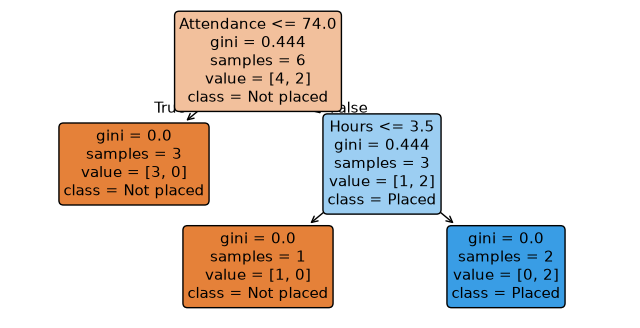

Prediction: [1]
Classes: [0 1]
Probabilities: [[0. 1.]]


In [ ]:
plt.figure(figsize=(8, 4))
plot_tree(nst_tree, feature_names=list(X_nst.columns),
          class_names=["Not placed", "Placed"], filled=True, rounded=True)
plt.show()

new_student = pd.DataFrame({"Hours": [7], "Attendance": [82]})
print("Prediction:", nst_tree.predict(new_student))
print("Classes:", nst_tree.classes_)
print("Probabilities:", nst_tree.predict_proba(new_student))
assert nst_tree.get_depth() == 2 and nst_tree.get_n_leaves() == 3


### Supplied Visualization: Decision Regions

Each tree question creates a horizontal or vertical boundary. The Hours split applies only above the Attendance split.
Run this plotting cell as supplied; the modeling task is already complete.


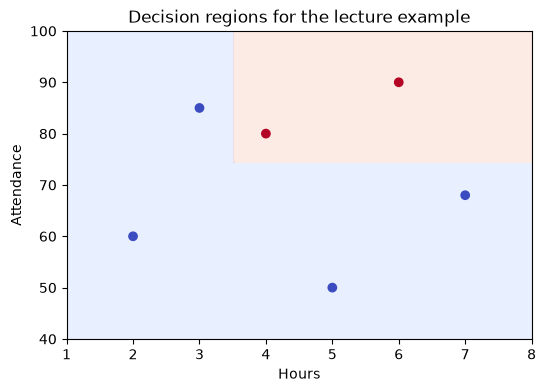

In [ ]:
h, a = np.meshgrid(np.linspace(1, 8, 100), np.linspace(40, 100, 100))
grid = pd.DataFrame({"Hours": h.ravel(), "Attendance": a.ravel()})
regions = nst_tree.predict(grid).reshape(h.shape)

plt.figure(figsize=(6, 4))
plt.contourf(h, a, regions, levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.2)
plt.scatter(nst["Hours"], nst["Attendance"], c=y_nst, cmap="coolwarm")
plt.xlabel("Hours")
plt.ylabel("Attendance")
plt.title("Decision regions for the lecture example")
plt.show()


### Check Your Understanding

Trace the new student manually. Why does predicting all six training rows correctly not establish future accuracy?

**Instructor answer:** 82 > 74, then 7 > 3.5, so the row reaches the Placed leaf. All six rows were used for fitting; they are not unseen evaluation data. A pure leaf or probability 1.0 is not a guarantee about future outcomes.


## Step 4: A Small Categorical-Input Example

For Education and Field, one-hot encoding creates category-membership columns.
Average Grade remains numerical. A Pipeline applies the same transformation during training and prediction.
This is the only categorical pipeline needed in this lab; the main rental model uses six numeric inputs.


In [ ]:
employment = pd.DataFrame({
    'Education': ['UG','UG','PG','PhD','PG','PhD','UG','PG','UG','PhD'],
    'Field': ['Science','Arts','Science','Science','Arts','Arts','Science','Arts','Arts','Science'],
    'Average Grade': [89,92,95,85,98,90,88,93,94,86],
    'Label': ['E','U','E','E','U','E','U','E','U','E'],
})
X_emp, y_emp = employment.drop(columns='Label'), employment['Label']
display(employment)


,Education,Field,Average Grade,Label
0,UG,Science,89,E
1,UG,Arts,92,U
2,PG,Science,95,E
3,PhD,Science,85,E
4,PG,Arts,98,U
5,PhD,Arts,90,E
6,UG,Science,88,U
7,PG,Arts,93,E
8,UG,Arts,94,U
9,PhD,Science,86,E


In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

preprocess = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"), ["Education", "Field"])
], remainder="passthrough")

employment_tree = Pipeline([
    ("encode", preprocess),
    ("tree", DecisionTreeClassifier(random_state=42))
])


### TODO 16.3

Fit the supplied pipeline, then predict the two new records. The second contains an unseen Education value.


In [ ]:
# TODO 16.3 — Fit the categorical decision-tree pipeline and make predictions.
# Instructions:
# 1. Fit employment_tree using X_emp and y_emp.
# 2. Create the two new records shown below (one includes an unseen category).
# 3. Predict their labels and print the encoded feature names.
# Keep the variable names new_records and employment_tree unchanged.
# TODO: write the fitting and prediction code here.
pass

['E' 'E']
['categories__Education_PG' 'categories__Education_PhD'
 'categories__Education_UG' 'categories__Field_Arts'
 'categories__Field_Science' 'remainder__Average Grade']


### Check Your Understanding

What does Education_UG ≤ 0.5 mean? Why avoid arbitrary category numbers? What does handle_unknown="ignore" guarantee?

**Instructor answer:** It tests whether the row is outside the UG category. Arbitrary numbers impose an order and restrict category groupings in one threshold. Unknown categories become zero indicators in their block, so transformation can proceed; prediction reliability for that unfamiliar category is not established.


## Step 5: Load Real Rental Records and Split the Data

The main model uses six inputs: hour, normalized temperature, normalized humidity, normalized wind speed,
working-day indicator, and year indicator. The last two are binary. No scaling or encoder is needed for these inputs.

**Exclude `casual` and `registered`: their sum equals the target `cnt`.** They would reveal the answer.
The rental records are time-ordered, so use `shuffle=False` to train on earlier rows and validate on later rows.


In [ ]:
# Supplied data-loading cell. No extra package is needed.
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
if not Path("hour.csv").exists():
    if not Path("bike_sharing.zip").exists():
        urlretrieve(url, "bike_sharing.zip")
    with ZipFile("bike_sharing.zip") as archive:
        Path("hour.csv").write_bytes(archive.read("hour.csv"))

data = pd.read_csv("hour.csv")
data = data.sort_values(["dteday", "hr"]).reset_index(drop=True)
print("Number of hourly records:", len(data))


Number of hourly records: 17379


### TODO 16.4

Create the busy-hour target and complete the two chronological splits. Reserving 25% of the remaining
80% gives 20% of the original data for validation.


In [ ]:
# Completed solution 16.4
features = ["hr", "temp", "hum", "windspeed", "workingday", "yr"]
data["busy"] = (data["cnt"] >= 300).astype(int)


# Keep earlier observations before later ones: shuffle=False is essential.
development, test = train_test_split(data, test_size=0.20, shuffle=False)
train, validation = train_test_split(development, test_size=0.25, shuffle=False)

X_train = train[features]
X_val = validation[features]
X_test = test[features]
y_train = train["busy"]
y_val = validation["busy"]
y_test = test["busy"]

print("Train:", len(train), "Validation:", len(validation), "Test:", len(test))


Train: 10427 Validation: 3476 Test: 3476


In [ ]:
# Supplied self-checks and results
assert len(train) + len(validation) + len(test) == len(data)
assert train.index.max() < validation.index.min() < test.index.min()
assert not {"cnt", "casual", "registered", "busy", "instant"}.intersection(features)
print("Checks passed. The final test set remains unused until Lab 17.")


Checks passed. The final test set remains unused until Lab 17.


In [ ]:
# Inspect training data only.
display(X_train.head())
display(X_train.dtypes)
display(X_train.isna().sum())
display(X_train.describe())
print("Training class counts:")
print(y_train.value_counts())


,hr,temp,hum,windspeed,workingday,yr
0,0,0.24,0.81,0.0,0,0
1,1,0.22,0.80,0.0,0,0
2,2,0.22,0.80,0.0,0,0
3,3,0.24,0.75,0.0,0,0
4,4,0.24,0.75,0.0,0,0


hr              int64
temp          float64
hum           float64
windspeed     float64
workingday      int64
yr              int64
dtype: object

hr            0
temp          0
hum           0
windspeed     0
workingday    0
yr            0
dtype: int64

,hr,temp,hum,windspeed,workingday,yr
count,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000
mean,11.560756,0.459676,0.630670,0.195572,0.682843,0.170902
std,6.908435,0.197383,0.197766,0.125696,0.465392,0.376442
min,0.000000,0.020000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,0.300000,0.470000,0.104500,0.000000,0.000000
50%,12.000000,0.440000,0.620000,0.194000,1.000000,0.000000
75%,18.000000,0.620000,0.790000,0.283600,1.000000,0.000000
max,23.000000,0.960000,1.000000,0.850700,1.000000,1.000000


Training class counts:
busy
0    8973
1    1454
Name: count, dtype: int64


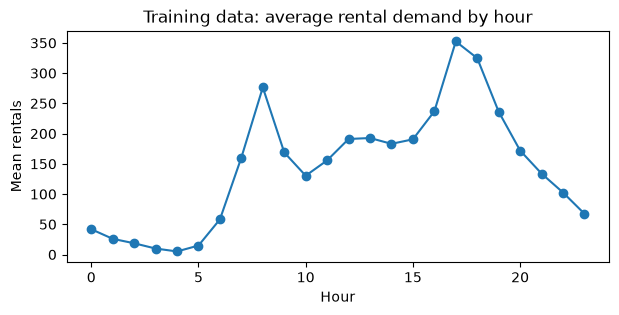

Always-predict-majority validation accuracy: 0.6294591484464902


In [ ]:
hourly_average = train.groupby("hr")["cnt"].mean()
plt.figure(figsize=(7, 3))
plt.plot(hourly_average.index, hourly_average.values, marker="o")
plt.xlabel("Hour")
plt.ylabel("Mean rentals")
plt.title("Training data: average rental demand by hour")
plt.show()

majority_class = y_train.mode()[0]
print("Always-predict-majority validation accuracy:", (y_val == majority_class).mean())


### Check Your Understanding

Why is accuracy compared with an always-predict-majority rule? Why are target components excluded?

**Instructor answer:** The baseline shows whether a tree adds value beyond the common class. The class balance may change in later periods. casual and registered are known after rentals occur and sum to cnt, so they leak the outcome rather than help make an advance prediction.


## Step 6: Compare Simple and Detailed Demand Rules

Fit three fixed models: depth 1, depth 3, and unrestricted. Keep the data unchanged.
A shallow model can miss useful structure; a deep one can fit details that do not generalize.
Judge the measured training and validation results, not depth alone.


### TODO 16.5

Complete the constructor, fit, and accuracy calculations. The loop records results for comparison.


In [ ]:
# TODO 16.5 — Compare decision trees with different maximum depths.
# Instructions:
# 1. Loop over depths [1, 3, None].
# 2. For each depth, create and fit a DecisionTreeClassifier.
# 3. Calculate training and validation accuracy, depth, and number of leaves.
# 4. Store each result in results and create depth_results with the same columns as below.
# Keep the variable names and column names unchanged; the next cell plots depth_results.
# TODO: write the model-comparison logic here.
pass

,max_depth,train_accuracy,val_accuracy,depth,leaves
0,1,0.860554,0.629459,1,2
1,3,0.883476,0.724108,3,7
2,None,0.998849,0.841197,22,724


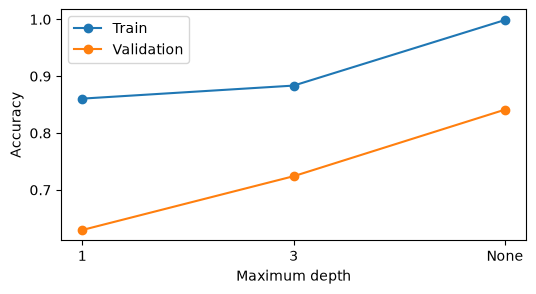

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(depth_results["max_depth"], depth_results["train_accuracy"], "o-", label="Train")
plt.plot(depth_results["max_depth"], depth_results["val_accuracy"], "o-", label="Validation")
plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


### Check Your Understanding

Which model has the largest train–validation gap? Relate a false negative and a false positive to this demand problem.

**Instructor answer:** Use the displayed scores to identify the actual gap. A false negative misses an hour with at least 300 rentals; a false positive flags a quieter hour as busy. They can imply insufficient or unnecessary preparation, but this dataset does not measure the cost or benefit of an operational action.


## Step 7: Predict a Number with a Regression Tree

Classification predicts busy/not busy. Regression estimates the rental count.
A squared-error leaf predicts the mean target of its training rows:

$$\hat y_{leaf}=\frac{1}{n_{leaf}}\sum_{i\in leaf}y_i$$

First verify the idea on the eight-row lecture example, then use it for the real rental data.


In [ ]:
score_records = pd.DataFrame({
    'Subject': ['Math','Physics','Physics','Math','Physics','Physics','Physics','Physics'],
    'Grade level': ['Freshman','Freshman','Freshman','Junior','Sophomore','Junior','Junior','Freshman'],
    'Hours': [4,1,4,6,1,3,4,9],
    'Test Score': [59,82,81,60,73,85,61,78],
})
X_small_reg, y_small_reg = score_records.drop(columns='Test Score'), score_records['Test Score']
display(score_records)


,Subject,Grade level,Hours,Test Score
0,Math,Freshman,4,59
1,Physics,Freshman,1,82
2,Physics,Freshman,4,81
3,Math,Junior,6,60
4,Physics,Sophomore,1,73
5,Physics,Junior,3,85
6,Physics,Junior,4,61
7,Physics,Freshman,9,78


In [ ]:
# Reuse the categorical-encoding idea for the lecture regression table.
score_encoder = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Subject", "Grade level"])
], remainder="passthrough")
encoded_scores = score_encoder.fit_transform(X_small_reg)


### TODO 16.6

Fit the squared-error tree with at least two rows in each leaf. Calculate MSE using predictions.


In [ ]:
# TODO 16.6 — Train a regression decision tree and evaluate it.
# Instructions:
# 1. Create a DecisionTreeRegressor with min_samples_leaf=2, criterion="squared_error",
#    and random_state=42.
# 2. Fit it on encoded_scores and y_small_reg.
# 3. Predict the training scores and print the mean squared error (MSE).
# Keep the variable names small_regressor and small_predictions unchanged.
# TODO: write the model creation, fitting, prediction, and MSE code here.
pass

Training MSE: 37.145833333333336


,target,prediction
leaf,,
2,73.000000,73.000000
3,80.333333,80.333333
4,59.500000,59.500000


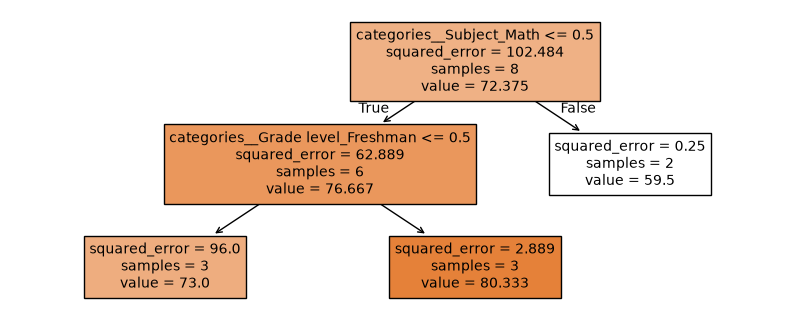

In [ ]:
leaf_id = small_regressor.apply(encoded_scores)
leaf_table = pd.DataFrame({"leaf": leaf_id, "target": y_small_reg, "prediction": small_predictions})
display(leaf_table.groupby("leaf")[["target", "prediction"]].mean())
assert np.isclose(mean_squared_error(y_small_reg, small_predictions), 37.1458333333)

plt.figure(figsize=(10, 4))
plot_tree(small_regressor, feature_names=list(score_encoder.get_feature_names_out()), filled=True)
plt.show()


In [ ]:
new_score = pd.DataFrame({"Subject": ["Physics"], "Grade level": ["Freshman"], "Hours": [5]})
print("Predicted score:", small_regressor.predict(score_encoder.transform(new_score)))


Predicted score: [80.33333333]


### Rental-Count Regression

Use the same feature rows, now with the actual rental count as the target.

$$MSE=\frac{1}{n}\sum_i(y_i-\hat y_i)^2$$

Lower MSE is better. MSE has squared rental-count units; RMSE is in rentals per hourly record.
Do not use `.score()` for MSE: a regressor's `.score()` returns R².


In [ ]:
# Same rows, different target: count rather than busy/not busy.
yr_train = train["cnt"]
yr_val = validation["cnt"]
yr_test = test["cnt"]


### TODO 16.7

Complete prediction and MSE calculations for the supplied depth-3 and unrestricted regressors.


In [ ]:
# TODO 16.7 — Compare regression trees with different maximum depths.
# Instructions:
# 1. Loop over max_depth values 3 and None.
# 2. Create and fit a DecisionTreeRegressor for each depth.
# 3. Predict for the training and validation sets and calculate both MSE values.
# 4. Append each fitted model to regressors and each result row to regression_results.
# The next cell uses regressors to plot piecewise-constant predictions.
# TODO: write the regression-model comparison logic here.
pass

,max_depth,train_MSE,val_MSE
0,3,9129.750262,32589.433283
1,None,27.547041,11695.713664


### Supplied Plot: Piecewise-Constant Predictions

Vary only hour and keep the other inputs at one training record. This is a conditional model profile,
not an observed daily curve or the causal effect of changing the hour.


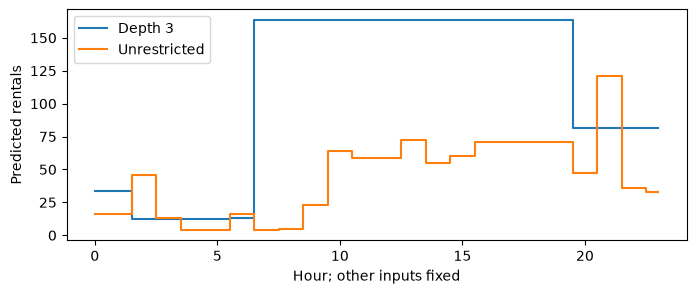

,temp,hum,windspeed,workingday,yr
0,0.24,0.81,0.0,0.0,0.0


In [ ]:
profile = pd.DataFrame([X_train.iloc[0].to_dict()] * 24)
profile["hr"] = range(24)

plt.figure(figsize=(8, 3))
plt.step(profile["hr"], regressors[0].predict(profile), where="mid", label="Depth 3")
plt.step(profile["hr"], regressors[1].predict(profile), where="mid", label="Unrestricted")
plt.xlabel("Hour; other inputs fixed")
plt.ylabel("Predicted rentals")
plt.legend()
plt.show()
display(profile.iloc[[0]].drop(columns="hr"))


### Check Your Understanding

Why do regression predictions form steps? Can a standard tree extrapolate a rising trend? What would a real demand service still need?

**Instructor answer:** Each leaf returns one constant mean. A standard tree does not extrapolate a rising trend beyond its learned regions. Later-period evaluation, weather forecasts available at prediction time, and a defined action policy are needed. System-wide rentals cannot determine station-level moves or quantify unmet requests.
